# Paper figures: main results

Makes the main results figures and table for the paper, from iteration 03's runs on Qwen3-8B (`output/03_epoch_ablation/`, one run per reward):

- **Figure 1:** library use over training, on the training data's held-out test split and on LibReuseBench test.
- **Table 1:** the selected checkpoints against the base model, on LibReuseBench test and control, HumanEval+ and LiveCodeBench.
- **Figure 2:** the plain prompt against the suffix *"Use an external library when appropriate."*, for the base model and each selected checkpoint.

**The selected checkpoints** are import epoch 2, usage epoch 3 and target epoch 3. Each is the epoch with the most LibReuseBench test library use (plain prompt) among epochs 1-3, the only epochs also evaluated with the suffix. Target epoch 4 is 0.1 points higher, but has no suffix results. The choice looks at test results, so it is a best-case preliminary selection, not a validation-selected optimum.

**How the values are computed** (as in `05_prompt_engineering_comparison.ipynb`):

- every metric is averaged within each task's 5 samples, then over tasks;
- error bars are ±1 standard error over tasks;
- differences against the base model have a 95% paired-bootstrap interval over tasks (10,000 resamples);
- **library use** is the share of responses that import and use a third-party library, and **high-value reuse** is library use on the test tasks in the high reuse tier (a library saves 15 or more lines);
- **lines saved**: an answer that uses a library saves however many logical lines shorter it is than the base model's average hand-written answer (plain prompt) to the same task, and an answer without a library saves 0. Tasks the base model never answered by hand are left out;
- **tokens**: the tokens generated per response, reasoning included.

The figures (PNG) and the LaTeX table are saved in `output/03_epoch_ablation/figures/`.

In [1]:
"""Make the main results figures and table for the paper."""

import json
import math
import os
from functools import cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from llm_cgr import load_jsonl
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from matplotlib.ticker import PercentFormatter

from src.utils.config import load_model_settings
from src.utils.paths import baseline_dir, model_output_dir


# run from the repo root (the folder holding .git), so the relative paths src uses
# (config/, output/) resolve - this notebook lives beside its results, in output/
REPO_ROOT = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / ".git").exists()
)
os.chdir(REPO_ROOT)

BASE_MODEL = "qwen3-8b"
# iteration 03's training runs, by the reward each was trained with
RUNS = {
    "import": "qwen3-8b-4474",
    "usage": "qwen3-8b-cc26",
    "target": "qwen3-8b-1f71",
}
EPOCHS = range(1, 9)
# the checkpoint of each run used in table 1 and figure 2 (see the notes at the top),
# chosen from the epochs that were also evaluated with the prompt suffix
SELECTED_EPOCHS = {"import": 2, "usage": 3, "target": 3}
SUFFIX_EPOCHS = range(1, 4)
DECODING_PROFILE = "default_16k"

# the prompt styles, as the result files name them: the task as it is ("base"), or with
# the suffix "Use an external library when appropriate." appended
PROMPT_STYLES = ["base", "appropriate"]

BOOTSTRAP_RESAMPLES = 10_000
OUTPUT_DIR = Path("output") / "03_epoch_ablation" / "figures"

In [2]:
# paper style: white background, light horizontal grid lines, no borders but the baseline
INK = "#3d3d3a"  # text
RULE = "#c3c2b7"  # axis baseline
GRID = "#e6e5df"  # grid lines

plt.rcParams.update(
    {
        "figure.dpi": 130,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "axes.edgecolor": RULE,
        "axes.labelcolor": INK,
        "axes.titlesize": 9,
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.spines.left": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": RULE,
        "xtick.labelcolor": INK,
        "ytick.labelcolor": INK,
        "ytick.major.size": 0,
        "font.size": 8,
        "legend.frameon": False,
        "legend.fontsize": 8,
    }
)

# figures span both columns of the paper, about 7 inches wide on the page. they are
# drawn wider and scaled down to fit, so the 8pt text is about 6pt in the paper
FIGURE_WIDTH = 9.0
FIGURE_HEIGHT = 3.6

# one colour and marker per reward, the same in every figure. the colours are three slots
# of a categorical palette, checked for colour-blindness against white with a palette
# validator, and the marker shapes tell the rewards apart in greyscale too
REWARD_COLOURS = {
    "import": "#eb6834",  # orange
    "usage": "#1155b9",  # the paper's blue, as usage is the default reward
    "target": "#a25ddc",  # purple
}
REWARD_MARKERS = {"import": "o", "usage": "s", "target": "^"}
BASE_COLOUR = "#6f6f6b"  # the base model, a neutral grey

# figure 2's colours show the prompt: light blue for the plain prompt, the paper's blue
# for the suffix (checked as a light-to-dark pair against white with a palette validator)
PROMPT_COLOURS = {"base": "#7aa6e8", "appropriate": "#1155b9"}
PROMPT_LABELS = {
    "base": "Plain prompt",
    "appropriate": "+ “Use an external library when appropriate.”",
}


def save_figure(
    fig: Figure,
    name: str,
) -> None:
    """Save a figure as a PNG in the figures folder."""
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(
        OUTPUT_DIR / f"{name}.png",
        dpi=300,
        bbox_inches="tight",
    )

## Results from the saved generations

Every value is computed from the per-response records each eval saved (`*.generations.jsonl`). The last check confirms the selected checkpoints are still each run's most library use among epochs 1-3.

In [3]:
# imported here, after the move to the repo root, as the benchmark package is not installed
from benchmark.libreusebench.evaluate import reuse_tier


def results_dir(
    reward: str | None,
    epoch: int,
) -> Path:
    """
    The folder of a model's eval results: the base model's (no reward), or one run's
    checkpoint at one epoch.

    Returns the folder path.
    """
    if reward is None:
        return baseline_dir(BASE_MODEL)
    model_key = f"{RUNS[reward]}-epoch{epoch}"
    return model_output_dir(
        model_key=model_key,
        model_settings=load_model_settings(model_key=model_key),
    )


@cache
def load_records(
    folder: Path,
    dataset: str,
    style: str,
) -> pd.DataFrame:
    """
    Load the records of one eval, one row per generated response.

    Returns the records.
    """
    path = folder / f"{dataset}-{DECODING_PROFILE}-{style}.generations.jsonl"
    return pd.DataFrame(load_jsonl(file_path=str(path)))


@cache
def hand_written_lines(
    dataset: str,
) -> pd.Series:
    """
    The base model's average hand-written answer (no library, plain prompt) to each task,
    in logical lines of code. A library-using answer is compared with it.

    Returns the lines of code per task, for the tasks the base model answered by hand.
    """
    records = load_records(
        folder=results_dir(reward=None, epoch=0),
        dataset=dataset,
        style="base",
    )
    by_hand = records[records["lloc"].notna() & ~records["external_lib_used"]]
    return by_hand.groupby("task_id")["lloc"].mean()


def task_values(
    reward: str | None,
    epoch: int,
    dataset: str,
    style: str,
    metric: str,
) -> pd.Series:
    """
    A metric's average over each task's samples, for one model, benchmark and prompt
    style. The metrics are "library use", "high-value reuse", "pass@1", "lines saved" and
    "tokens" (see the notes at the top). Tasks with no value, such as ones the base model never
    answered by hand, are left out.

    Returns one value per task, indexed by task id.
    """
    records = load_records(
        folder=results_dir(reward=reward, epoch=epoch),
        dataset=dataset,
        style=style,
    )
    if metric == "high-value reuse":
        records = records[records["reuse_value"].map(reuse_tier) == "high"]
    if metric in {"library use", "high-value reuse"}:
        values = records["external_lib_used"].astype(float)
    elif metric == "pass@1":
        values = records["passed"].astype(float)
    elif metric == "lines saved":
        # shorter than the hand-written reference if it uses a library, else 0
        reference = records["task_id"].map(hand_written_lines(dataset=dataset))
        values = (reference - records["lloc"]).where(records["external_lib_used"], 0.0)
        values = values.where(records["lloc"].notna() & reference.notna())
    elif metric == "tokens":
        values = records["completion_tokens"].astype(float)
    else:
        raise ValueError(f"unknown metric: {metric}")
    return values.groupby(records["task_id"]).mean().dropna()


def mean_and_error(
    values: pd.Series,
) -> tuple[float, float]:
    """
    Average per-task values over tasks.

    Returns the mean and its standard error over tasks.
    """
    return values.mean(), values.std(ddof=1) / math.sqrt(len(values))


def paired_bootstrap(
    trained: pd.Series,
    base: pd.Series,
) -> tuple[float, float, float]:
    """
    Compare two models on the same tasks: resample the tasks with replacement many times,
    and take the average per-task difference each time. Only tasks both models have a
    value for are compared.

    Returns the difference (trained minus base) and its 95% percentile interval.
    """
    differences = (trained - base).dropna().to_numpy()
    # a fixed seed, so the intervals are the same every time the notebook runs
    rng = np.random.default_rng(seed=0)
    picks = rng.integers(
        len(differences),
        size=(BOOTSTRAP_RESAMPLES, len(differences)),
    )
    lower, upper = np.percentile(differences[picks].mean(axis=1), [2.5, 97.5])
    return differences.mean(), lower, upper


# check each selected checkpoint is its run's most library use on libreusebench test
# (plain prompt) among the epochs also evaluated with the suffix
for reward, selected in SELECTED_EPOCHS.items():
    use = {
        epoch: task_values(
            reward=reward,
            epoch=epoch,
            dataset="libreusebench_test",
            style="base",
            metric="library use",
        ).mean()
        for epoch in SUFFIX_EPOCHS
    }
    best = max(use, key=lambda epoch: use[epoch])
    assert best == selected, (
        f"{reward}: most library use at epoch {best}, not {selected}"
    )
print("selected checkpoints:", SELECTED_EPOCHS)

selected checkpoints: {'import': 2, 'usage': 3, 'target': 3}


## Figure 1: learning the reward and transferring reuse

Both panels measure the same thing for every reward, use of any third-party library, so the runs can be compared directly. The training reward itself is not plotted, as its definition differs between runs.

- **(a)** The training data's held-out test split (145 prompts from 19 tasks training never sees), scored during training every 5 steps with 5 answers per prompt. Each epoch's point is the round nearest the epoch's end, and epoch 0 is step 0 (the base model).
- **(b)** LibReuseBench test (216 tasks, 5 samples each, plain prompt). Each run's selected checkpoint is ringed and labelled with its value. Usage and target share a point at epoch 3, so they share a label.

**Draft caption.** *Training and transfer of library-use behaviour.* (a) Library use on held-out feature requests from the training-data test split increases throughout GRPO training. (b) Transfer to LibReuseBench peaks much earlier, at approximately 37.5%, before declining with further optimisation. Labelled points mark the checkpoints used for subsequent preliminary analyses: import epoch 2, usage epoch 3, and target epoch 3. Each evaluation uses five samples per request.

In [4]:
ALL_EPOCHS = [0, *EPOCHS]

# (a) the held-out test split's rounds during training, from each run's trainer state
held_out_rows = []
for reward in RUNS:
    run_dir = results_dir(reward=reward, epoch=1).parent
    trainer_state = json.loads((run_dir / "grpo" / "trainer_state.json").read_text())
    steps_per_epoch = math.ceil(
        trainer_state["max_steps"] / trainer_state["num_train_epochs"],
    )
    # the share of answers using a third-party library, at each round
    rounds = pd.Series(
        {
            entry["step"]: entry["eval_test/external_lib_used"]
            for entry in trainer_state["log_history"]
            if "eval_test/external_lib_used" in entry
        }
    )
    for epoch in ALL_EPOCHS:
        # the round nearest the epoch's end
        step = rounds.index[np.abs(rounds.index - epoch * steps_per_epoch).argmin()]
        held_out_rows.append(
            {
                "reward": reward,
                "epoch": epoch,
                "step": step,
                "library use": rounds[step],
            }
        )
held_out = pd.DataFrame(held_out_rows)
print(
    "held-out rounds used, by epoch:",
    held_out.groupby("epoch")["step"].first().to_dict(),
)

# (b) libreusebench test, plain prompt, at every epoch (epoch 0 is the base model)
transfer = pd.DataFrame(
    [
        {
            "reward": reward,
            "epoch": epoch,
            "library use": task_values(
                reward=None if epoch == 0 else reward,
                epoch=epoch,
                dataset="libreusebench_test",
                style="base",
                metric="library use",
            ).mean(),
        }
        for reward in RUNS
        for epoch in ALL_EPOCHS
    ]
)

# the table view of the figure
display(
    pd.concat(
        {
            "(a) held-out training requests": held_out.pivot(
                index="epoch",
                columns="reward",
                values="library use",
            )[list(RUNS)],
            "(b) LibReuseBench test": transfer.pivot(
                index="epoch",
                columns="reward",
                values="library use",
            )[list(RUNS)],
        },
        axis=1,
    ).style.format("{:.1%}")
)

held-out rounds used, by epoch: {0: 0, 1: 35, 2: 75, 3: 110, 4: 150, 5: 185, 6: 220, 7: 260, 8: 295}


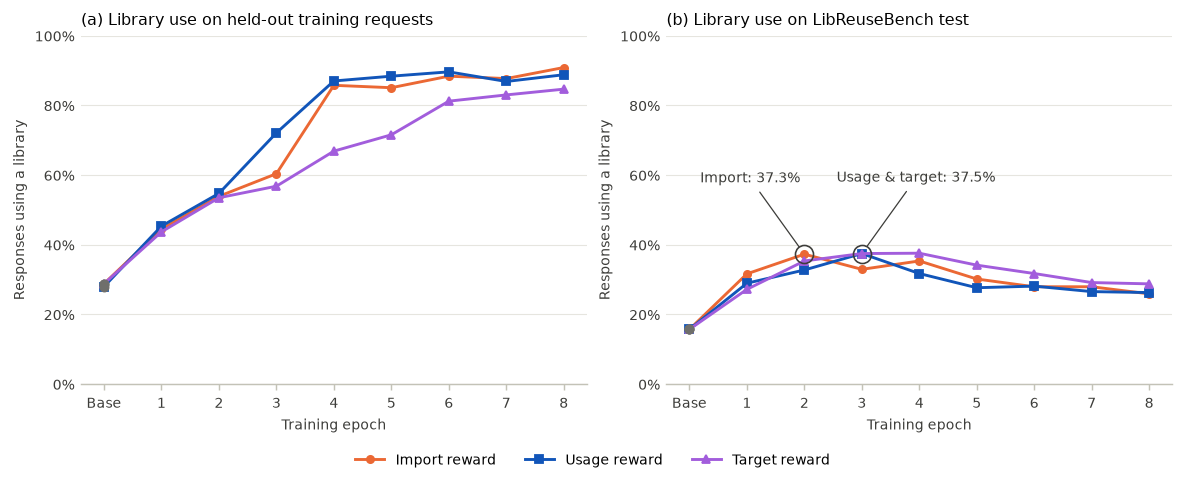

In [5]:
def plot_library_use_curve(
    ax: Axes,
    data: pd.DataFrame,
    title: str,
    annotate_selected: bool = False,
) -> None:
    """
    Draw one panel of figure 1: library use per epoch, one line per reward, with the base
    model's point (epoch 0) in grey. `annotate_selected` rings each run's selected
    checkpoint and labels it with its value, with one label for runs that share a point.
    """
    for reward in RUNS:
        line = data[data["reward"] == reward].set_index("epoch")["library use"]
        ax.plot(
            line.index,
            line.values,
            color=REWARD_COLOURS[reward],
            marker=REWARD_MARKERS[reward],
            markersize=4,
            linewidth=1.6,
            label=f"{reward.capitalize()} reward",
        )
        ax.plot(
            0,
            line[0],
            color=BASE_COLOUR,
            marker="o",
            markersize=4.5,
            linestyle="none",
            zorder=3,
        )

    if annotate_selected:
        # the selected points, merging runs at the same epoch with the same value shown
        values = data.set_index(["reward", "epoch"])["library use"]
        points: dict[tuple[int, str], tuple[float, list[str]]] = {}
        for reward, epoch in SELECTED_EPOCHS.items():
            value = values[reward, epoch]
            points.setdefault((epoch, f"{value:.1%}"), (value, []))[1].append(reward)
        # the labels fan out left and right, so neighbouring labels don't overlap
        for index, ((epoch, shown), (value, rewards)) in enumerate(
            sorted(points.items())
        ):
            ax.plot(
                epoch,
                value,
                marker="o",
                markersize=10,
                markerfacecolor="none",
                markeredgecolor=INK,
                markeredgewidth=0.9,
                linestyle="none",
                zorder=4,
            )
            ax.annotate(
                f"{' & '.join(rewards).capitalize()}: {shown}",
                xy=(epoch, value),
                xytext=((index - (len(points) - 1) / 2) * 60, 38),
                textcoords="offset points",
                ha="center",
                va="bottom",
                color=INK,
                fontsize=7.5,
                arrowprops={
                    "arrowstyle": "-",
                    "color": INK,
                    "linewidth": 0.7,
                    "shrinkA": 2,
                    "shrinkB": 5,
                },
            )

    ax.set_title(title)
    ax.set_xticks(
        ALL_EPOCHS,
        labels=["Base", *(str(epoch) for epoch in EPOCHS)],
    )
    ax.set_xlim(-0.4, max(EPOCHS) + 0.4)
    ax.set_xlabel("Training epoch")
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.set_ylabel("Responses using a library")


fig, axes = plt.subplots(
    1,
    2,
    figsize=(FIGURE_WIDTH, FIGURE_HEIGHT),
    layout="constrained",
)
plot_library_use_curve(
    ax=axes[0],
    data=held_out,
    title="(a) Library use on held-out training requests",
)
plot_library_use_curve(
    ax=axes[1],
    data=transfer,
    title="(b) Library use on LibReuseBench test",
    annotate_selected=True,
)
handles, _ = axes[0].get_legend_handles_labels()
fig.legend(
    handles=handles,
    loc="outside lower center",
    ncols=len(handles),
)
save_figure(fig=fig, name="figure_1_training_and_transfer")
plt.show()

## Table 1: main results

The base model against each run's selected checkpoint, all with the plain prompt.

The caption says correctness is preserved. The notebook checks this: it prints each trained model's pass@1 difference from the base model with its 95% paired-bootstrap interval, and stops if any interval excludes zero.

The table is saved as LaTeX. It needs the `booktabs` and `adjustbox` packages, and the paper's name macros (`\lure`, `\qwlil`, `\libreusebench`, `\humaneval`, `\livecodebench`).

**Caption.** *Effect of LURe training on Qwen3-8B.* Results use the selected preliminary checkpoints for each reward. Training substantially increases library reuse while preserving correctness on LibReuseBench, its control split, and general coding benchmarks.

In [6]:
# the rows: the base model, then each run at its selected checkpoint
TABLE_MODELS = {
    "Qwen3-8B": (None, 0),
    **{
        f"+ {reward.capitalize()} reward (epoch {epoch})": (reward, epoch)
        for reward, epoch in SELECTED_EPOCHS.items()
    },
}
# the columns, in their groups: (group, heading, dataset, metric)
TABLE_COLUMNS = [
    ("LibReuseBench test", "Library use", "libreusebench_test", "library use"),
    (
        "LibReuseBench test",
        "High-value reuse",
        "libreusebench_test",
        "high-value reuse",
    ),
    ("LibReuseBench test", "pass@1", "libreusebench_test", "pass@1"),
    ("LibReuseBench test", "Lines saved", "libreusebench_test", "lines saved"),
    ("LibReuseBench test", "Tokens", "libreusebench_test", "tokens"),
    ("Control", "Library use", "libreusebench_control", "library use"),
    ("Control", "pass@1", "libreusebench_control", "pass@1"),
    ("Regression pass@1", "HumanEval+", "humaneval_plus", "pass@1"),
    ("Regression pass@1", "LiveCodeBench", "livecodebench", "pass@1"),
]
cells = pd.DataFrame(
    [
        {
            "model": model,
            "dataset": dataset,
            "metric": metric,
            "value": task_values(
                reward=reward,
                epoch=epoch,
                dataset=dataset,
                style="base",
                metric=metric,
            ).mean(),
        }
        for model, (reward, epoch) in TABLE_MODELS.items()
        for _, _, dataset, metric in TABLE_COLUMNS
    ]
).set_index(["model", "dataset", "metric"])["value"]

# the note under the table says no change in correctness is distinguishable from the base
# model, so check each trained model's pass@1 interval includes zero
for model, (reward, epoch) in TABLE_MODELS.items():
    if reward is None:
        continue
    for _, _, dataset, metric in TABLE_COLUMNS:
        if metric != "pass@1":
            continue
        difference, lower, upper = paired_bootstrap(
            trained=task_values(
                reward=reward,
                epoch=epoch,
                dataset=dataset,
                style="base",
                metric=metric,
            ),
            base=task_values(
                reward=None,
                epoch=0,
                dataset=dataset,
                style="base",
                metric=metric,
            ),
        )
        print(
            f"{model}, {dataset} pass@1: {difference * 100:+.1f} "
            f"[{lower * 100:+.1f}, {upper * 100:+.1f}]"
        )
        assert lower <= 0 <= upper, f"{model}, {dataset}: the interval excludes zero"


def format_value(
    value: float,
    metric: str,
) -> str:
    """
    Write a value as the table shows it.

    Returns lines to one decimal, a whole number of tokens, or a percentage to one
    decimal for a rate.
    """
    if metric == "lines saved":
        return f"{value:.1f}"
    if metric == "tokens":
        return f"{value:,.0f}"
    return f"{value:.1%}"


# the notebook's view of the table
display(
    pd.DataFrame(
        {
            (group, heading): [
                format_value(value=cells[model, dataset, metric], metric=metric)
                for model in TABLE_MODELS
            ]
            for group, heading, dataset, metric in TABLE_COLUMNS
        },
        index=list(TABLE_MODELS),
    )
)

+ Import reward (epoch 2), libreusebench_test pass@1: +3.7 [-0.2, +7.4]
+ Import reward (epoch 2), libreusebench_control pass@1: +1.4 [-3.6, +6.2]


+ Import reward (epoch 2), humaneval_plus pass@1: -1.0 [-2.7, +0.6]
+ Import reward (epoch 2), livecodebench pass@1: +2.3 [-1.1, +5.7]


+ Usage reward (epoch 3), libreusebench_test pass@1: -0.5 [-4.1, +3.0]
+ Usage reward (epoch 3), libreusebench_control pass@1: -1.4 [-4.8, +1.9]


+ Usage reward (epoch 3), humaneval_plus pass@1: +0.5 [-1.5, +2.4]


+ Usage reward (epoch 3), livecodebench pass@1: +2.8 [-1.8, +7.4]
+ Target reward (epoch 3), libreusebench_test pass@1: +2.5 [-1.0, +6.0]


+ Target reward (epoch 3), libreusebench_control pass@1: +1.7 [-2.6, +6.0]


+ Target reward (epoch 3), humaneval_plus pass@1: -1.0 [-2.9, +1.0]
+ Target reward (epoch 3), livecodebench pass@1: +3.4 [-0.5, +7.4]


LibReuseBench test                          \
                                 Library use High-value reuse pass@1   
Qwen3-8B                               15.7%            39.6%  75.5%   
+ Import reward (epoch 2)              37.3%            71.5%  79.2%   
+ Usage reward (epoch 3)               37.5%            71.9%  75.0%   
+ Target reward (epoch 3)              37.5%            70.8%  78.0%   

                                                 Control         \
                          Lines saved Tokens Library use pass@1   
Qwen3-8B                          0.7  9,158        0.0%  80.5%   
+ Import reward (epoch 2)         4.0  6,814        0.0%  81.9%   
+ Usage reward (epoch 3)          3.8  7,229        0.5%  79.0%   
+ Target reward (epoch 3)         4.1  7,138        0.2%  82.1%   

                          Regression pass@1                
                                 HumanEval+ LiveCodeBench  
Qwen3-8B                              89.6%         66.9%  
+ Import reward (epoch 2)             88.7%         69.2%  
+ Usage reward (epoch 3)              90.1%         69.7%  
+ Target reward (epoch 3)             88.7%         70.3%

In [7]:
# the paper's macros for names, and pass@1 in italics
LATEX_NAMES = {
    "Qwen3-8B": r"\qwlil",
    "HumanEval+": r"\humaneval",
    "LiveCodeBench": r"\livecodebench",
    "pass@1": r"\textit{pass@1}",
}


def latex(
    text: str,
) -> str:
    """
    Write a table cell for LaTeX: escape the characters LaTeX treats specially, and use
    the paper's macros for names.

    Returns the LaTeX text.
    """
    text = text.replace("%", r"\%")
    for name, macro in LATEX_NAMES.items():
        text = text.replace(name, macro)
    return text


rows = [
    " & ".join(
        [
            latex(model),
            *(
                latex(format_value(value=cells[model, dataset, metric], metric=metric))
                for _, _, dataset, metric in TABLE_COLUMNS
            ),
        ]
    )
    + r" \\"
    for model in TABLE_MODELS
]

lines = [
    r"\begin{table*}[t]",
    r"\centering",
    "",
    r"\caption{",
    r"\textbf{Effect of \lure{} training on \qwlil.}",
    r"Results use the selected preliminary checkpoints for each reward.",
    r"Training substantially increases library reuse while preserving correctness on "
    r"\libreusebench, its control split, and general coding benchmarks.",
    r"}",
    "",
    r"\label{tab:main-results}",
    "",
    r"    \begin{adjustbox}{width=\textwidth}",
    r"    \bgroup",
    r"    \def\arraystretch{1.4}",
    "",
    r"\begin{tabular}{lrrrrrrrrr}",
    r"\toprule",
    r" & \multicolumn{5}{c}{\libreusebench{} test} & \multicolumn{2}{c}{Control}"
    r" & \multicolumn{2}{c}{Regression \textit{pass@1}} \\",
    r"\cmidrule(lr){2-6} \cmidrule(lr){7-8} \cmidrule(lr){9-10}",
    " & ".join(["Model", *(latex(heading) for _, heading, _, _ in TABLE_COLUMNS)])
    + r" \\",
    r"\midrule",
    *rows,
    r"\bottomrule",
    r"\end{tabular}",
    r"\egroup",
    r"    \end{adjustbox}",
    r"\end{table*}",
]
table_file = OUTPUT_DIR / "table_1_main_results.tex"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
table_file.write_text("\n".join(lines) + "\n")
print(table_file.read_text())

\begin{table*}[t]
\centering

\caption{
\textbf{Effect of \lure{} training on \qwlil.}
Results use the selected preliminary checkpoints for each reward.
Training substantially increases library reuse while preserving correctness on \libreusebench, its control split, and general coding benchmarks.
}

\label{tab:main-results}

    \begin{adjustbox}{width=\textwidth}
    \bgroup
    \def\arraystretch{1.4}

\begin{tabular}{lrrrrrrrrr}
\toprule
 & \multicolumn{5}{c}{\libreusebench{} test} & \multicolumn{2}{c}{Control} & \multicolumn{2}{c}{Regression \textit{pass@1}} \\
\cmidrule(lr){2-6} \cmidrule(lr){7-8} \cmidrule(lr){9-10}
Model & Library use & High-value reuse & \textit{pass@1} & Lines saved & Tokens & Library use & \textit{pass@1} & \humaneval & \livecodebench \\
\midrule
\qwlil & 15.7\% & 39.6\% & 75.5\% & 0.7 & 9,158 & 0.0\% & 80.5\% & 89.6\% & 66.9\% \\
+ Import reward (epoch 2) & 37.3\% & 71.5\% & 79.2\% & 4.0 & 6,814 & 0.0\% & 81.9\% & 88.7\% & 69.2\% \\
+ Usage reward (epoch 3) &

## Figure 2: prompting and training are complementary

LibReuseBench test, for the base model and each selected checkpoint, with the plain prompt and with the suffix *"Use an external library when appropriate."*. Colour shows the prompt here, not the reward.

**Draft caption.** *Training and prompt engineering are complementary.* Library use and code saved on LibReuseBench when models are evaluated with the standard task prompt or with the suffix ``Use an external library when appropriate.'' Prompting alone substantially increases reuse, while applying the same instruction after LURe training increases it further. The target-reward checkpoint with the suffix reaches 74.6% library use and saves 8.3 logical lines per response on average. Lines saved: how many logical lines shorter a library-using answer is than the base model's average hand-written answer to the same task (0 for an answer without a library). Error bars show ±1 standard error over tasks.

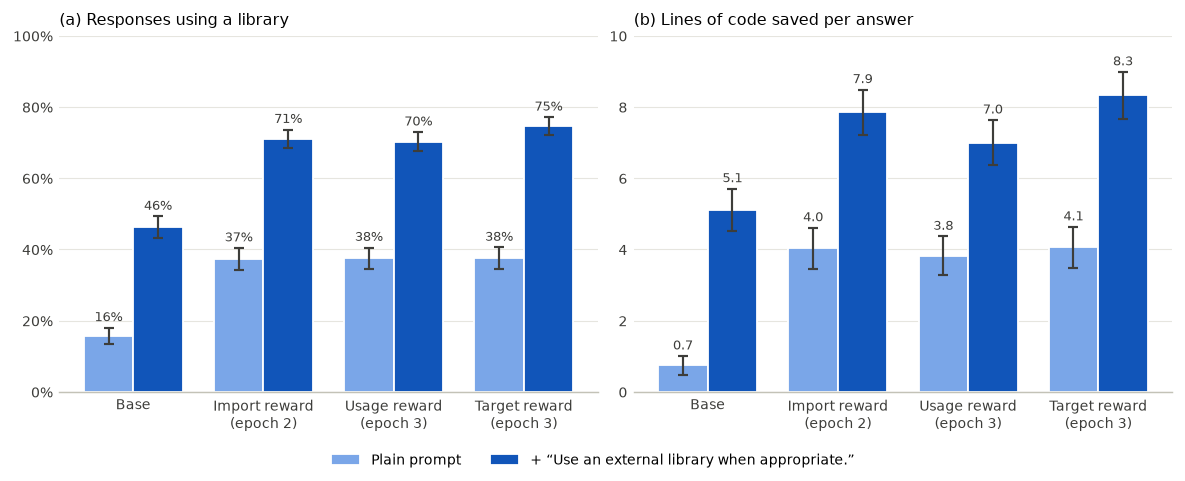

In [8]:
# the groups of bars: the base model, then each run at its selected checkpoint
FIGURE_2_MODELS = {
    "Base": (None, 0),
    **{
        f"{reward.capitalize()} reward\n(epoch {epoch})": (reward, epoch)
        for reward, epoch in SELECTED_EPOCHS.items()
    },
}

bar_rows = []
for model, (reward, epoch) in FIGURE_2_MODELS.items():
    for style in PROMPT_STYLES:
        for metric in ["library use", "lines saved"]:
            mean, error = mean_and_error(
                task_values(
                    reward=reward,
                    epoch=epoch,
                    dataset="libreusebench_test",
                    style=style,
                    metric=metric,
                )
            )
            bar_rows.append(
                {
                    "model": model,
                    "style": style,
                    "metric": metric,
                    "value": mean,
                    "standard_error": error,
                }
            )
bars = pd.DataFrame(bar_rows)

# the table view of the figure
display(
    bars.pivot_table(
        index=["model", "style"],
        columns="metric",
        values=["value", "standard_error"],
        sort=False,
    ).style.format("{:.3f}")
)


def plot_prompt_bars(
    ax: Axes,
    metric: str,
    title: str,
) -> None:
    """
    Draw one panel of figure 2: a pair of bars per model (plain prompt, then the suffix),
    each with its standard error and its value above it.
    """
    is_rate = metric == "library use"
    positions = np.arange(len(FIGURE_2_MODELS))
    width = 0.38
    for offset, style in zip([-0.5, 0.5], PROMPT_STYLES):
        group = (
            bars[(bars["metric"] == metric) & (bars["style"] == style)]
            .set_index("model")
            .reindex(list(FIGURE_2_MODELS))
        )
        x = positions + offset * width
        ax.bar(
            x,
            group["value"],
            width=width,
            color=PROMPT_COLOURS[style],
            # a thin white gap between the two bars of a pair
            edgecolor="white",
            linewidth=1,
            label=PROMPT_LABELS[style],
        )
        ax.errorbar(
            x,
            group["value"],
            yerr=group["standard_error"],
            fmt="none",
            ecolor=INK,
            elinewidth=1.2,
            capsize=3,
            capthick=1.2,
        )
        for bar_x, value, error in zip(x, group["value"], group["standard_error"]):
            ax.annotate(
                f"{value:.0%}" if is_rate else f"{value:.1f}",
                xy=(bar_x, value + error),
                xytext=(0, 2),
                textcoords="offset points",
                ha="center",
                va="bottom",
                color=INK,
                fontsize=7,
            )
    ax.set_title(title)
    ax.set_xticks(positions, labels=list(FIGURE_2_MODELS))
    ax.tick_params(axis="x", length=0)
    if is_rate:
        ax.set_ylim(0, 1)
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    else:
        # from 0 to 10 lines, or the next whole line if a bar and its label need more
        ax.set_ylim(0, max(10, math.ceil(ax.get_ylim()[1])))


fig, axes = plt.subplots(
    1,
    2,
    figsize=(FIGURE_WIDTH, FIGURE_HEIGHT),
    layout="constrained",
)
plot_prompt_bars(
    ax=axes[0],
    metric="library use",
    title="(a) Responses using a library",
)
plot_prompt_bars(
    ax=axes[1],
    metric="lines saved",
    title="(b) Lines of code saved per answer",
)
handles, _ = axes[0].get_legend_handles_labels()
fig.legend(
    handles=handles,
    loc="outside lower center",
    ncols=2,
)
save_figure(fig=fig, name="figure_2_prompting_and_training")
plt.show()